# Historical recoveries for $\sqrt e$

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    hermite_exponential_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, y0 = sp.symbols('x0 y0')
z = sp.Rational(1, 2)
target = lambda: (arb(1)/2).exp()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Hermite (1873): Family A: Padé type $(N,N)$

[Cohn (2006), Proposition 1 and Lemma 1](https://arxiv.org/pdf/math/0601660).

**CMF:** ${}_1F_1(z)$, rank 2. **Start:** $(1;2)$. **Direction:** $(1;2)$.
**Readout:** $(PW)_0/(QW)_0$ using the exact Hermite seed rows. N is the source index.

In [5]:
cmf = pFq(1, 1, z)
start = {x0: 1, y0: 2}
trajectory = {x0: 1, y0: 2}
P, Q = hermite_exponential_seeds(z, 'A')
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Hermite A'] = (DEPTHS, deltas)
accuracy['Hermite A'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 1.002084356813


## 2. Hermite (1873): Family B: Padé type $(N,N+1)$

[Cohn (2006), Proposition 1 and Lemma 1](https://arxiv.org/pdf/math/0601660).

**CMF:** ${}_1F_1(z)$, rank 2. **Start:** $(2;3)$. **Direction:** $(1;2)$.
**Readout:** $(PW)_0/(QW)_0$ using the exact Hermite seed rows. N is the source index.

In [7]:
cmf = pFq(1, 1, z)
start = {x0: 2, y0: 3}
trajectory = {x0: 1, y0: 2}
P, Q = hermite_exponential_seeds(z, 'B')
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Hermite B'] = (DEPTHS, deltas)
accuracy['Hermite B'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 1.000189658099


## 3. Hermite (1873): Family C: Padé type $(N+1,N)$

[Cohn (2006), Proposition 1 and Lemma 1](https://arxiv.org/pdf/math/0601660).

**CMF:** ${}_1F_1(z)$, rank 2. **Start:** $(1;3)$. **Direction:** $(1;2)$.
**Readout:** $(PW)_0/(QW)_0$ using the exact Hermite seed rows. N is the source index.

In [9]:
cmf = pFq(1, 1, z)
start = {x0: 1, y0: 3}
trajectory = {x0: 1, y0: 2}
P, Q = hermite_exponential_seeds(z, 'C')
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Hermite C'] = (DEPTHS, deltas)
accuracy['Hermite C'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 1.000189657800


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

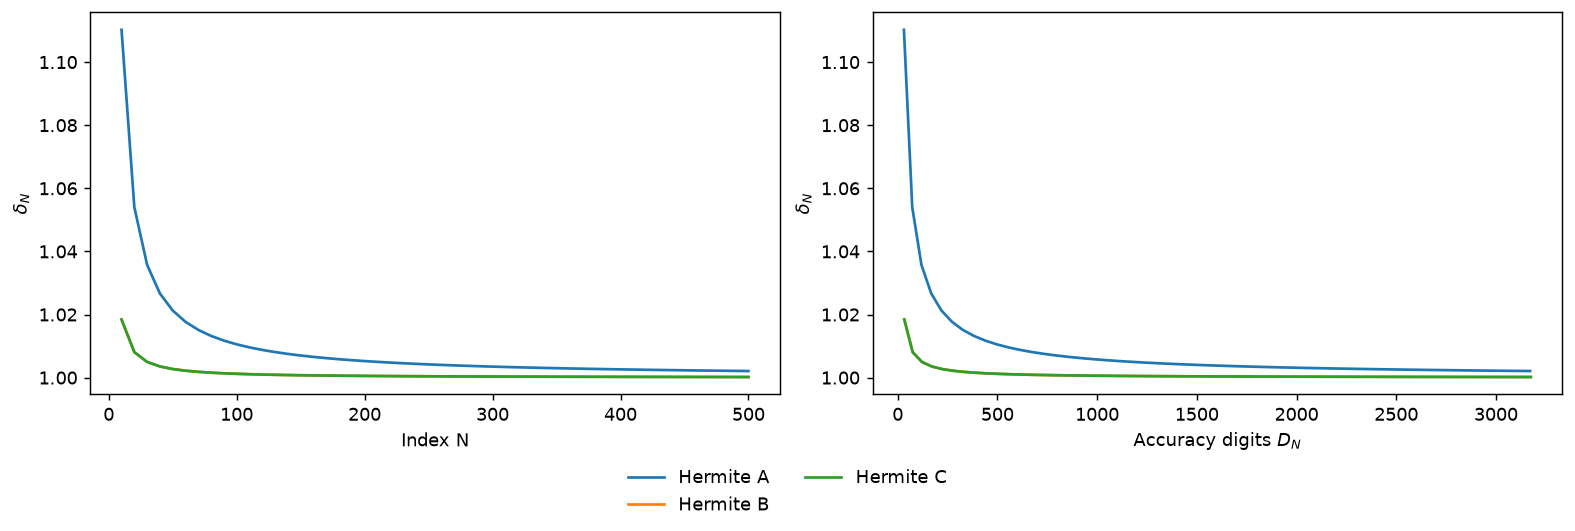

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [13]:
bounds = {
    'Hermite A': 'General exponential Padé formula; no numerical bound quoted',
    'Hermite B': 'General exponential Padé formula; no numerical bound quoted',
    'Hermite C': 'General exponential Padé formula; no numerical bound quoted',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Hermite A | General exponential Padé formula; no numerical bound quoted | 1.002084356813 (N = 500) |
| Hermite B | General exponential Padé formula; no numerical bound quoted | 1.000189658099 (N = 500) |
| Hermite C | General exponential Padé formula; no numerical bound quoted | 1.000189657800 (N = 500) |